# Figure 2: Predictive interval coverage

Recompute coverage directly from saved probability integral transforms (PITs). Coverage is tested on the spectroscopic overlap and does not prove population-wide or conditional calibration.

Run all cells in a Python environment with `requirements/notebooks.txt` installed. The plotting style follows SpenderQ methods_paper and requires latex and dvipng. Inputs are frozen, documented snapshots in `paper/data/`; no training or network access is required. The final cell writes both PDF and PNG versions into `paper/figures/`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'paper/data/predictions.npz').exists())
sys.path.insert(0, str(ROOT / 'src'))
from pzflow.paper_utils import (COLORS, LABELS, set_style, load_predictions,
                         load_metrics, summary, bootstrap, save_figure)
set_style()

In [2]:
d = load_predictions(ROOT)
names = ['cosmos_pdf_flow', 'broadband_spec_flow', 'eazy_rprior', 'lephare_full_cosmos']
alpha = np.linspace(0, 1, 101)
curves = {}
for name in names:
    pit = d[f'{name}_pit']
    ranks = np.abs(2 * pit - 1)
    curve = np.array([(ranks <= a).mean() for a in alpha])
    # Exact endpoints can be affected by clipped or rounded CDF tails.
    curve[0], curve[-1] = 0., 1.
    curves[name] = curve
    print(name, 'C68/C95:', [(ranks <= a).mean() for a in [.68, .95]])

cosmos_pdf_flow C68/C95: [np.float64(0.6858154633090694), np.float64(0.9472752311626992)]
broadband_spec_flow C68/C95: [np.float64(0.6596498131024985), np.float64(0.9396025968915994)]
eazy_rprior C68/C95: [np.float64(0.598858941569939), np.float64(0.8555970883336612)]
lephare_full_cosmos C68/C95: [np.float64(0.5634467833956325), np.float64(0.8195947275231162)]


The shaded band is a 95% pointwise galaxy-bootstrap interval for the bootstrapped flow (300 resamples, fixed seed). It excludes training-seed variance, spatial covariance and spectroscopic-selection uncertainty.

In [3]:
rng = np.random.default_rng(20261117)
ranks = np.abs(2 * d['cosmos_pdf_flow_pit'] - 1)
order = np.searchsorted(np.sort(ranks), alpha, side='right')
draws = np.empty((300, len(alpha)))
for b in range(len(draws)):
    sample = np.sort(ranks[rng.integers(0, len(ranks), len(ranks))])
    draws[b] = np.searchsorted(sample, alpha, side='right') / len(sample)
lower, upper = np.quantile(draws, [.025, .975], axis=0)

Saved paper/figures/fig03_calibration.pdf and .png


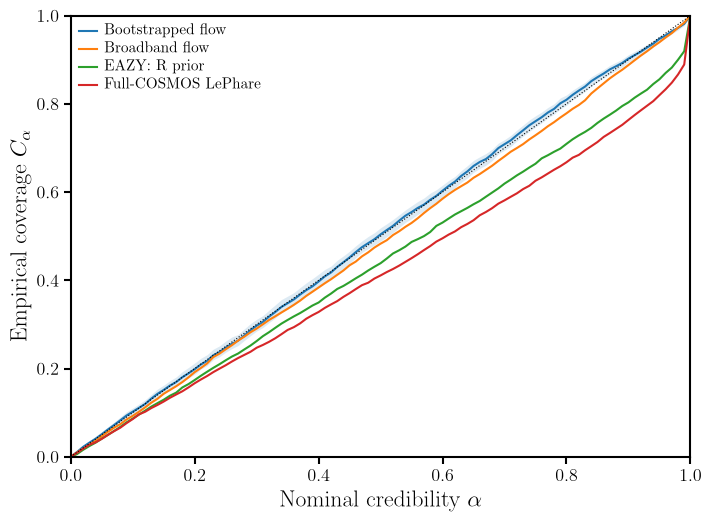

In [4]:
fig, ax = plt.subplots(figsize=(3.5, 2.55), layout='constrained')
ax.fill_between(alpha, lower, upper, color=COLORS['cosmos_pdf_flow'], alpha=.15, lw=0)
for name in names:
    ax.plot(alpha, curves[name], color=COLORS[name], label=LABELS[name])
ax.plot([0, 1], [0, 1], color='black', ls=':', lw=.8)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel=r'Nominal credibility $\alpha$', ylabel=r'Empirical coverage $C_\alpha$')
ax.legend(loc='upper left', frameon=False, fontsize=6.5)
save_figure(fig, ROOT, 'fig03_calibration')
plt.show()
plt.close(fig)